In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Dataset .csv")
print(df.shape)

(9551, 21)


Restaurants with valid coordinates: 9052 / 9551


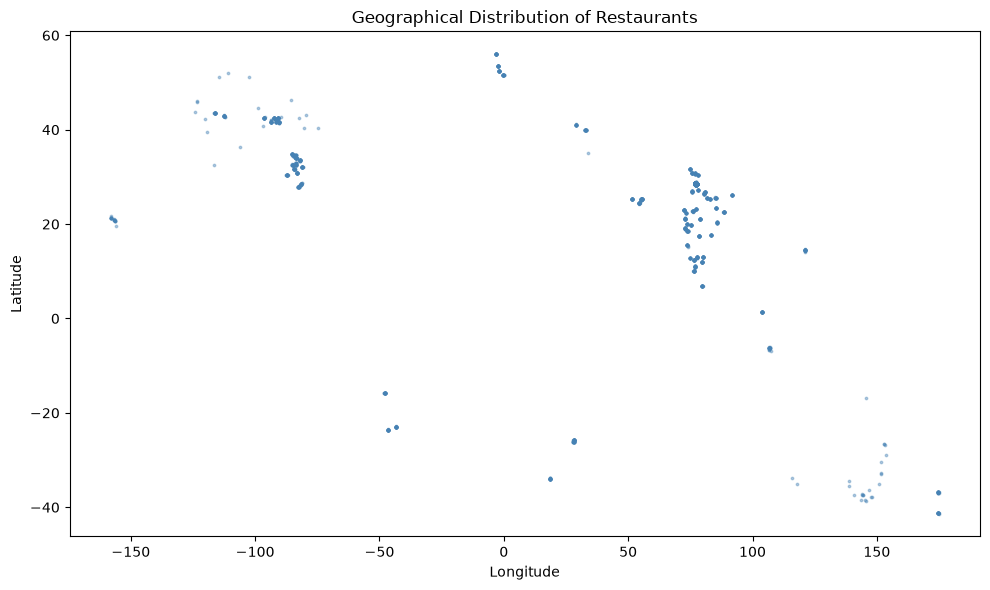

In [3]:
geo = df[(df["Latitude"] != 0) & (df["Longitude"] != 0)]
print(f"Restaurants with valid coordinates: {len(geo)} / {len(df)}")

plt.figure(figsize=(10, 6))
plt.scatter(geo["Longitude"], geo["Latitude"], s=3, alpha=0.4, c="steelblue")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Distribution of Restaurants")
plt.tight_layout()
plt.show()

Top 10 cities by restaurant count:
City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Ahmedabad         21
Amritsar          21
Bhubaneshwar      21
Guwahati          21
Lucknow           21
Name: count, dtype: int64


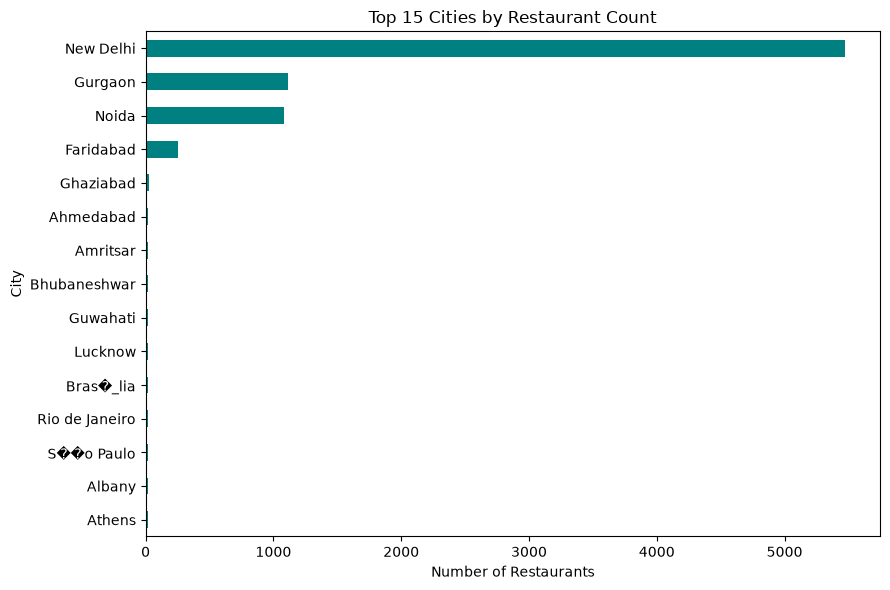

In [4]:
city_counts = df["City"].value_counts()
print("Top 10 cities by restaurant count:")
print(city_counts.head(10))

plt.figure(figsize=(9, 6))
city_counts.head(15).plot(kind="barh", color="teal")
plt.gca().invert_yaxis()
plt.xlabel("Number of Restaurants")
plt.title("Top 15 Cities by Restaurant Count")
plt.tight_layout()
plt.show()

In [5]:
MIN_RESTAURANTS = 20
eligible_cities = city_counts[city_counts >= MIN_RESTAURANTS].index

city_stats = (
    df[df["City"].isin(eligible_cities)]
    .groupby("City")
    .agg(
        Restaurant_Count=("Restaurant ID", "count"),
        Avg_Rating=("Aggregate rating", "mean"),
        Avg_Cost_For_Two=("Average Cost for two", "mean"),
        Avg_Price_Range=("Price range", "mean"),
        Avg_Votes=("Votes", "mean"),
    )
    .sort_values("Avg_Rating", ascending=False)
)
print(f"Top 15 cities by average rating (min {MIN_RESTAURANTS} restaurants):")
print(city_stats.head(15).round(2))

Top 15 cities by average rating (min 20 restaurants):
                 Restaurant_Count  Avg_Rating  Avg_Cost_For_Two  \
City                                                              
London                         20        4.54             64.50   
Orlando                        20        4.47             40.25   
Rest of Hawaii                 20        4.41             31.75   
Tampa Bay                      20        4.41             34.75   
Bangalore                      20        4.38           1232.50   
Dubai                          20        4.37            211.75   
Chennai                        20        4.31           1085.00   
Ankara                         20        4.30             87.25   
Abu Dhabi                      20        4.30            182.00   
Auckland                       20        4.28             68.25   
Rio de Janeiro                 20        4.26            126.75   
Boise                          20        4.26             27.25   
Kolkata 

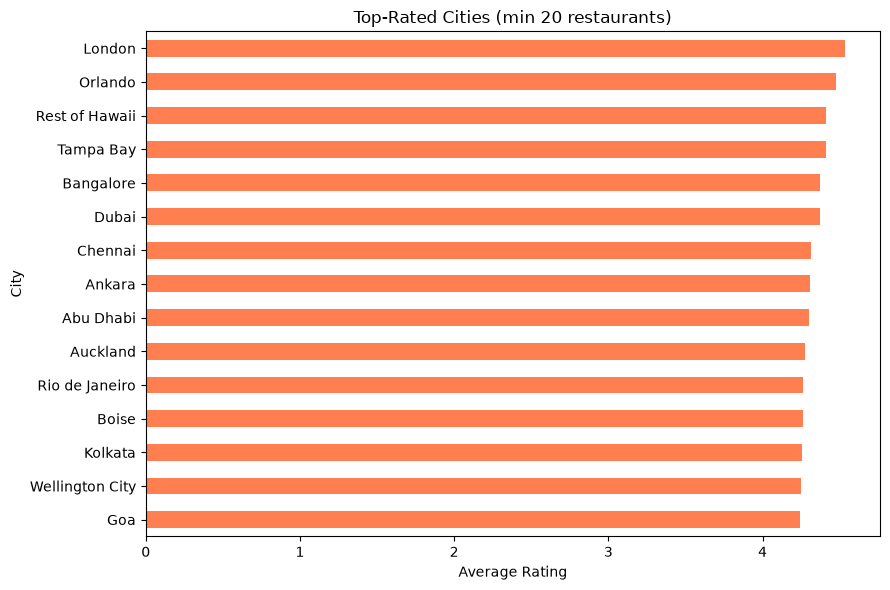

In [6]:
plt.figure(figsize=(9, 6))
city_stats["Avg_Rating"].head(15).plot(kind="barh", color="coral")
plt.gca().invert_yaxis()
plt.xlabel("Average Rating")
plt.title(f"Top-Rated Cities (min {MIN_RESTAURANTS} restaurants)")
plt.tight_layout()
plt.show()

In [7]:
df["Cuisines"] = df["Cuisines"].fillna("Unknown")
df["Primary Cuisine"] = df["Cuisines"].apply(lambda x: x.split(",")[0].strip())

top_5_cities = city_counts.head(5).index
print("Most common primary cuisine in top 5 cities by restaurant count:")
for city in top_5_cities:
    top_cuisine = df[df["City"] == city]["Primary Cuisine"].value_counts().idxmax()
    n = df[df["City"] == city]["Primary Cuisine"].value_counts().max()
    total = city_counts[city]
    print(f"  {city}: {top_cuisine} ({n}/{total} restaurants)")

Most common primary cuisine in top 5 cities by restaurant count:
  New Delhi: North Indian (1848/5473 restaurants)
  Gurgaon: North Indian (367/1118 restaurants)
  Noida: North Indian (433/1080 restaurants)
  Faridabad: North Indian (102/251 restaurants)
  Ghaziabad: North Indian (9/25 restaurants)
